# Linear Regression
---

## Experiment: derive and visualize the least-squares line.

Intercept: 2.8995; slope: 1.7159
SSE: 177.1293
Sum of residuals: -1.226e-13
Sum of x * residuals: -5.986e-13


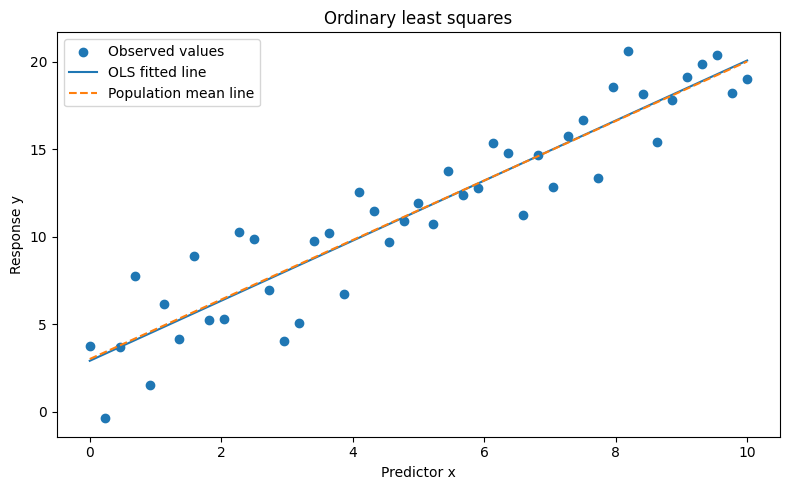

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(107)
x = np.linspace(0, 10, 45)
y = 3 + 1.7 * x + rng.normal(0, 2, size=x.size)

x_bar, y_bar = x.mean(), y.mean()
s_xx = np.sum((x - x_bar) ** 2)
s_xy = np.sum((x - x_bar) * (y - y_bar))
b1 = s_xy / s_xx
b0 = y_bar - b1 * x_bar
fitted = b0 + b1 * x
residuals = y - fitted

print(f"Intercept: {b0:.4f}; slope: {b1:.4f}")
print(f"SSE: {np.sum(residuals ** 2):.4f}")
print(f"Sum of residuals: {residuals.sum():.3e}")
print(f"Sum of x * residuals: {np.sum(x * residuals):.3e}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, label="Observed values")
ax.plot(x, fitted, label="OLS fitted line")
ax.plot(x, 3 + 1.7 * x, linestyle="--", label="Population mean line")
ax.set(xlabel="Predictor x", ylabel="Response y", title="Ordinary least squares")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/lr_ols_fit.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: compare NumPy, scikit-learn, and statsmodels.

In [2]:
import numpy as np
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression

rng = np.random.default_rng(108)
x = rng.normal(size=100)
y = 2.5 - 0.8 * x + rng.normal(0, 0.9, size=x.size)

X = np.column_stack([np.ones(x.size), x])
beta_numpy = np.linalg.lstsq(X, y, rcond=None)[0]
model_sklearn = LinearRegression().fit(x.reshape(-1, 1), y)
model_sm = sm.OLS(y, sm.add_constant(x)).fit()

print("NumPy (intercept, slope):", beta_numpy)
print("scikit-learn:", model_sklearn.intercept_, model_sklearn.coef_[0])
print("statsmodels:", model_sm.params)
print("Identical coefficients:", np.allclose(beta_numpy, model_sm.params))
print("R-squared:", model_sm.rsquared)
print("Residual standard error:", np.sqrt(model_sm.mse_resid))

NumPy (intercept, slope): [ 2.60512386 -1.0471138 ]
scikit-learn: 2.6051238643022785 -1.0471138015408215
statsmodels: [ 2.60512386 -1.0471138 ]
Identical coefficients: True
R-squared: 0.7022762944397467
Residual standard error: 0.8271415992949542


## Experiment: diagnose heteroskedastic residuals.

Breusch-Pagan LM statistic: 16.192, p-value: 5.724e-05
The test is a diagnostic; inspect the plot and sampling design too.


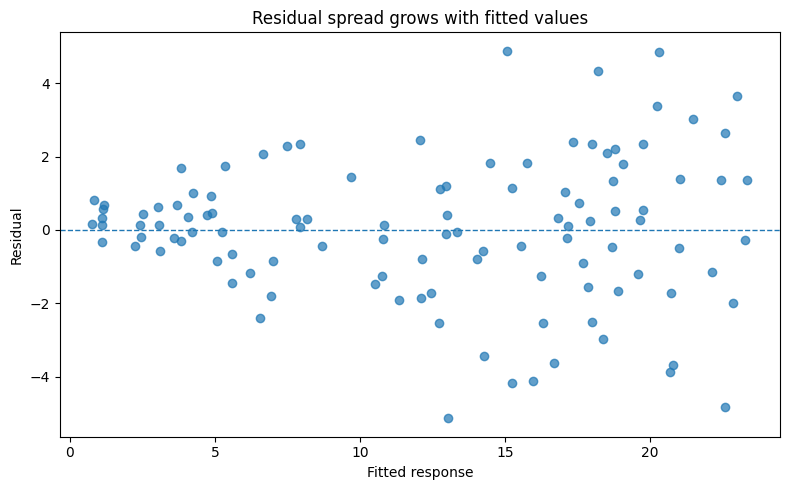

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

rng = np.random.default_rng(109)
x = rng.uniform(0, 10, 110)
y = 1 + 2.2 * x + rng.normal(0, 0.4 + 0.28 * x)
fit = sm.OLS(y, sm.add_constant(x)).fit()
lm, p_lm, _, _ = het_breuschpagan(fit.resid, fit.model.exog)
print(f"Breusch-Pagan LM statistic: {lm:.3f}, p-value: {p_lm:.4g}")
print("The test is a diagnostic; inspect the plot and sampling design too.")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(fit.fittedvalues, fit.resid, alpha=0.7)
ax.axhline(0, linestyle="--", linewidth=1)
ax.set(xlabel="Fitted response", ylabel="Residual", title="Residual spread grows with fitted values")
fig.tight_layout()
fig.savefig("../../images/lr_residual_diagnostics.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: inspect leverage and Cook’s distance.

In [4]:
import numpy as np
import statsmodels.api as sm

rng = np.random.default_rng(110)
x = np.linspace(-2, 2, 36)
y = 1.5 + 0.7 * x + rng.normal(0, 0.7, size=x.size)
x[-1], y[-1] = 8.0, -6.0  # Intentionally influential observation

full = sm.OLS(y, sm.add_constant(x)).fit()
without_last = sm.OLS(y[:-1], sm.add_constant(x[:-1])).fit()
influence = full.get_influence()
leverage = influence.hat_matrix_diag
cook = influence.cooks_distance[0]
index = int(np.argmax(cook))

print("Full-sample slope:", round(full.params[1], 4))
print("Slope without final observation:", round(without_last.params[1], 4))
print("Largest Cook's D at index:", index)
print("Its leverage and Cook's D:", round(leverage[index], 4), round(cook[index], 4))
print("Reference screening threshold 4/n:", round(4 / len(x), 4))

Full-sample slope: -0.2542
Slope without final observation: 0.6579
Largest Cook's D at index: 35
Its leverage and Cook's D: 0.5869 19.0725
Reference screening threshold 4/n: 0.1111


## Experiment: distinguish confidence and prediction intervals.

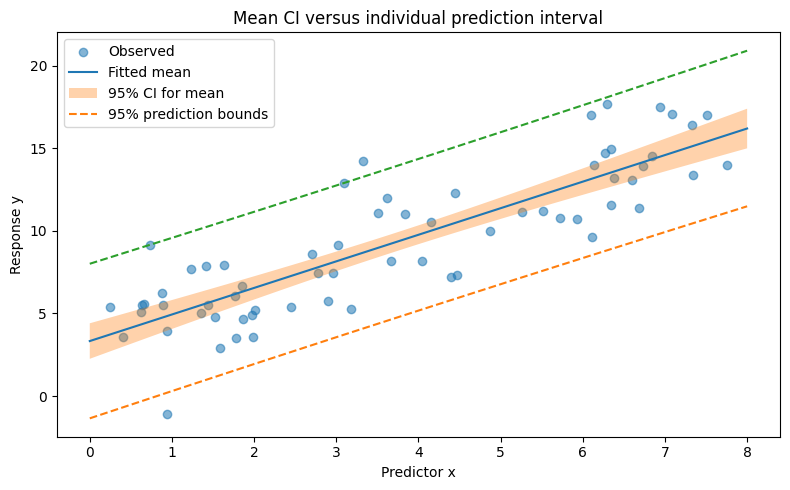

mean             3.328526
mean_ci_lower    2.254332
mean_ci_upper    4.402721
obs_ci_lower    -1.347985
obs_ci_upper     8.005037
Name: 0, dtype: float64


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

rng = np.random.default_rng(111)
x = rng.uniform(0, 8, size=65)
y = 4 + 1.35 * x + rng.normal(0, 2.2, size=x.size)
fit = sm.OLS(y, sm.add_constant(x)).fit()
grid = np.linspace(0, 8, 180)
frame = fit.get_prediction(sm.add_constant(grid)).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, alpha=0.55, label="Observed")
ax.plot(grid, frame["mean"], label="Fitted mean")
ax.fill_between(grid, frame["mean_ci_lower"], frame["mean_ci_upper"],
                alpha=0.35, label="95% CI for mean")
ax.plot(grid, frame["obs_ci_lower"], linestyle="--", label="95% prediction bounds")
ax.plot(grid, frame["obs_ci_upper"], linestyle="--")
ax.set(xlabel="Predictor x", ylabel="Response y", title="Mean CI versus individual prediction interval")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/lr_prediction_intervals.png", dpi=170, bbox_inches="tight")
plt.show()
print(frame.loc[0, ["mean", "mean_ci_lower", "mean_ci_upper", "obs_ci_lower", "obs_ci_upper"]])

##  Experiment: compare training and test error with a baseline.

In [6]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score

rng = np.random.default_rng(112)
x = rng.uniform(0, 10, 220)
y = 3 + 1.5 * x + 0.2 * x**2 + rng.normal(0, 2.0, x.size)
X = x.reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=112)

for name, model in [("Linear model", LinearRegression()),
                    ("Mean baseline", DummyRegressor(strategy="mean"))]:
    model.fit(X_train, y_train)
    for split, features, targets in [("train", X_train, y_train),
                                      ("test", X_test, y_test)]:
        pred = model.predict(features)
        rmse = np.sqrt(mean_squared_error(targets, pred))
        print(f"{name:13s} {split:5s}: RMSE={rmse:.3f}, R2={r2_score(targets, pred):.3f}")
print("The generating relationship is curved: inspect residuals before trusting extrapolation.")

Linear model  train: RMSE=2.284, R2=0.946
Linear model  test : RMSE=2.780, R2=0.923
Mean baseline train: RMSE=9.814, R2=0.000
Mean baseline test : RMSE=10.048, R2=-0.001
The generating relationship is curved: inspect residuals before trusting extrapolation.
